# Clasificación de variedades de frijol seco con K-NN
**Ingeniería del conocimiento · Proyecto final**

**Equipo:** _(escribir los nombres de los seis integrantes)_

**Contenido**
1. Problema y datos
2. Significado de las columnas
3. Herramientas utilizadas
4. Limpieza
5. Exploración: variedades
6. Entrenamiento
7. Elección de k
8. Prueba y métricas
9. Una predicción de ejemplo
10. Tablero en Power BI
11. Conclusión

> **Cómo ejecutar:** menú *Kernel > Restart Kernel and Run All Cells*. Este cuaderno necesita `Dry_Bean_Dataset.xlsx` y `limpieza.py` en la misma carpeta. Al ejecutarlo se generan `datos_limpios.csv` y `resultados_prueba.csv`.

## 1. Problema y datos
**Objetivo:** predecir la **variedad de un frijol seco** a partir de **16 medidas de su tamaño y forma**.

**Fuente:** Dry Bean Dataset, UCI Machine Learning Repository. Koklu, M. y Ozkan, I.A. (2020). *Multiclass Classification of Dry Beans Using Computer Vision and Machine Learning Techniques.* Computers and Electronics in Agriculture, 174, 105507.

**Cómo está organizada la tabla**
- Una **fila** es un frijol analizado.
- Las **16 columnas de medidas** describen su tamaño y forma. Son las pistas que usa el programa.
- La columna **Class** es la variedad real. Es la respuesta que se quiere predecir.

**Variedades:** BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER y SIRA.

**Idea de K-NN:** para clasificar un frijol nuevo, el programa busca los **k frijoles más parecidos** del conjunto de entrenamiento y elige la variedad que más se repite entre ellos.

## 2. Significado de las columnas (diccionario de datos)
Las medidas se obtuvieron analizando imágenes de cada frijol, por eso muchas vienen en píxeles.

| Campo | Tipo | Significado |
|---|---|---|
| Area | entero | Área del frijol: píxeles dentro de su contorno |
| Perimeter | decimal | Perímetro: longitud de su borde |
| MajorAxisLength | decimal | Eje mayor: la línea más larga que se puede trazar en el frijol |
| MinorAxisLength | decimal | Eje menor: la línea más larga perpendicular al eje mayor |
| AspectRation | decimal | Relación de aspecto: eje mayor / eje menor (así se escribe en el archivo) |
| Eccentricity | decimal | Excentricidad de la elipse con los mismos momentos que el frijol |
| ConvexArea | entero | Píxeles del polígono convexo más pequeño que contiene al frijol |
| EquivDiameter | decimal | Diámetro de un círculo con la misma área que el frijol |
| Extent | decimal | Proporción entre el área del frijol y la de su caja contenedora |
| Solidity | decimal | Área del frijol / área convexa |
| roundness | decimal | Redondez: 4·π·Area / Perimeter² |
| Compactness | decimal | Compacidad: EquivDiameter / MajorAxisLength |
| ShapeFactor1 | decimal | Factor de forma 1: MajorAxisLength / Area |
| ShapeFactor2 | decimal | Factor de forma 2: MinorAxisLength / Area |
| ShapeFactor3 | decimal | Factor de forma 3: Area / (π · (MajorAxisLength/2)²) |
| ShapeFactor4 | decimal | Factor de forma 4: Area / (π · (MajorAxisLength/2) · (MinorAxisLength/2)) |
| Class | texto | **Variedad real del frijol (lo que se quiere predecir)** |

Las medidas están en escalas muy distintas (Area llega a decenas de miles y Solidity es menor a 1), por eso se escalan antes de usar K-NN.

## 3. Herramientas utilizadas
- **Anaconda:** entorno de Python `ing-con`.
- **Python** con **pandas** (tablas), **scikit-learn** (modelo y métricas), **matplotlib** (gráficas) y **openpyxl** (leer el Excel).
- **Spyder:** escribir y ejecutar `limpieza.py`.
- **JupyterLab:** este cuaderno.
- **Power BI Desktop:** tablero con los resultados de prueba.

In [1]:
import sys
import pandas as pd
import sklearn, matplotlib, openpyxl
import matplotlib.pyplot as plt

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib  :", matplotlib.__version__)
print("openpyxl    :", openpyxl.__version__)

Python      : 3.10.22
pandas      : 2.3.3
scikit-learn: 1.7.2
matplotlib  : 3.10.9
openpyxl    : 3.1.5


## 4. Limpieza
`limpieza.py` lee el Excel, revisa celdas vacías, tipos de dato y duplicados, quita los **duplicados exactos** y guarda `datos_limpios.csv`. Se eliminan los duplicados **antes** de separar entrenamiento y prueba, para que una misma fila no quede en los dos grupos.

In [2]:
%run limpieza.py

Filas antes de limpiar: 13611
Columnas: 17
Celdas vacías: 0

Tipos de dato:
Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class               object
dtype: object

¿Las 16 medidas son numéricas? True
¿Hay medidas con valor cero o negativo? False

Variedades encontradas:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Filas duplicadas: 68
Filas después de limpiar: 13543
Filas eliminadas: 68

Archivo guardado: datos_limpios.csv


**Cambios realizados:** la tabla original tenía 13,611 filas y 17 columnas, sin celdas vacías y con las 16 medidas numéricas. Se encontraron **68 filas duplicadas exactas** y se eliminaron, conservando la primera aparición de cada una. Quedaron **13,543 filas**.

## 5. Exploración: cantidad de frijoles por variedad

In [3]:
datos = pd.read_csv("datos_limpios.csv")
print("Filas y columnas:", datos.shape)
datos.head()

Filas y columnas: (13543, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


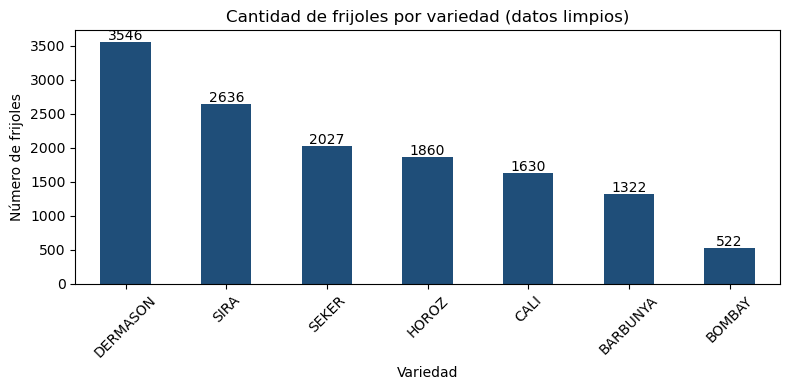

Suma de variedades: 13543 | Filas de la tabla: 13543


In [4]:
conteo = datos["Class"].value_counts()

ax = conteo.plot(kind="bar", figsize=(8, 4), color="#1F4E79")
plt.title("Cantidad de frijoles por variedad (datos limpios)")
plt.xlabel("Variedad")
plt.ylabel("Número de frijoles")
plt.xticks(rotation=45)
for i, valor in enumerate(conteo):
    ax.text(i, valor + 30, str(valor), ha="center")
plt.tight_layout()
plt.savefig("grafica_variedades.png", dpi=150)
plt.show()

print("Suma de variedades:", conteo.sum(), "| Filas de la tabla:", len(datos))

**Qué se observa:**
- **DERMASON** es la variedad más numerosa (3,546 frijoles, cerca del 26 %) y **BOMBAY** la menos numerosa (522, cerca del 4 %). DERMASON tiene casi 7 veces más ejemplos.
- Las variedades **no están balanceadas**.
- Por eso se separan los datos conservando las proporciones de cada variedad y, además de la exactitud, se reporta el **F1 macro**, que da el mismo peso a las siete variedades.

## 6. Entrenamiento
Se separa **una sola vez** el 80 % para entrenamiento y el 20 % para prueba, con proporciones parecidas de las siete variedades (`stratify`) y una semilla fija (`random_state=42`). El escalador y el modelo se ajustan **solo con el 80 %** de entrenamiento.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X = datos.drop(columns="Class")   # las 16 medidas (las pistas)
y = datos["Class"]                # la variedad real (la respuesta)
print("X tiene", X.shape[1], "columnas | ¿Class está en X?", "Class" in X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)
print("Entrenamiento:", len(X_train), "filas")
print("Prueba:       ", len(X_test), "filas")

X tiene 16 columnas | ¿Class está en X? False
Entrenamiento: 10834 filas
Prueba:        2709 filas


In [6]:
proporciones = pd.DataFrame({
    "completo_%": y.value_counts(normalize=True) * 100,
    "entrenamiento_%": y_train.value_counts(normalize=True) * 100,
    "prueba_%": y_test.value_counts(normalize=True) * 100,
}).round(2)
proporciones

,completo_%,entrenamiento_%,prueba_%
Class,,,
DERMASON,26.18,26.19,26.17
SIRA,19.46,19.47,19.45
SEKER,14.97,14.96,14.99
HOROZ,13.73,13.73,13.73
CALI,12.04,12.04,12.03
BARBUNYA,9.76,9.76,9.78
BOMBAY,3.85,3.86,3.84


In [7]:
K_ELEGIDO = 5

modelo = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=K_ELEGIDO)
)
modelo.fit(X_train, y_train)   # el escalador y K-NN solo ven entrenamiento
print("Modelo preparado con k =", K_ELEGIDO)

Modelo preparado con k = 5


- **StandardScaler** pone las medidas en escalas comparables. Sin él, Area dominaría las distancias.
- **KNeighborsClassifier** clasifica con los k vecinos más cercanos.
- Ajustar ambos solo con entrenamiento evita la **fuga de datos**: la prueba no influye en el modelo.

## 7. Elección de k
El plan parte de **k = 5 como opción básica**, no como el mejor valor. Para comprobarlo se compararon los valores de k de 1 a 25 con **validación cruzada de 5 partes usando solo el conjunto de entrenamiento**. El conjunto de prueba no se utilizó para esta elección.

Mejor k: 19 -> 92.48 %
k = 5  -> 92.09 %


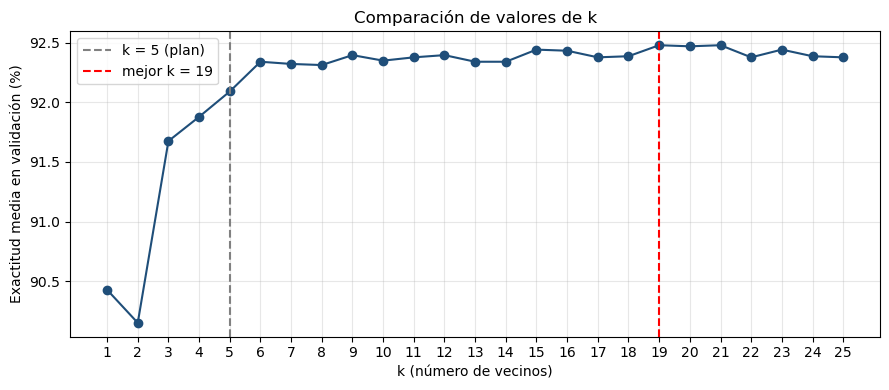

In [8]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
valores_k = list(range(1, 26))
exactitudes = []

for k in valores_k:
    candidato = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    exactitudes.append(cross_val_score(candidato, X_train, y_train, cv=cv).mean() * 100)

mejor_k = valores_k[exactitudes.index(max(exactitudes))]
print("Mejor k:", mejor_k, "->", round(max(exactitudes), 2), "%")
print("k = 5  ->", round(exactitudes[4], 2), "%")

plt.figure(figsize=(9, 4))
plt.plot(valores_k, exactitudes, marker="o", color="#1F4E79")
plt.axvline(5, color="gray", linestyle="--", label="k = 5 (plan)")
plt.axvline(mejor_k, color="red", linestyle="--", label=f"mejor k = {mejor_k}")
plt.xlabel("k (número de vecinos)")
plt.ylabel("Exactitud media en validación (%)")
plt.title("Comparación de valores de k")
plt.xticks(valores_k)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("grafica_k.png", dpi=150)
plt.show()

**Qué se observa:**
- Con k pequeño el modelo es menos preciso: k = 1 obtiene 90.43 % y k = 2 obtiene 90.15 %, el valor más bajo, porque pocos vecinos se dejan influir por ejemplos atípicos.
- La exactitud sube hasta k = 6 (alrededor de 92.3 %) y después se mantiene casi plana, entre 92.3 % y 92.5 %.
- El mejor resultado fue k = 19, con 92.48 %. Con k = 5 se obtuvo 92.09 %. La diferencia es de 0.39 puntos porcentuales.

**Decisión:** se conserva **k = 5**, como se planteó al inicio. Su resultado en validación (92.09 %) es muy cercano al mejor (92.48 %) y la gráfica confirma que k = 5 ya está en la zona donde el modelo se estabiliza.

## 8. Prueba y métricas
Se pide al modelo la variedad de cada frijol de prueba (2,709 frijoles que no vio al entrenar) y se compara con la variedad real.

In [9]:
y_pred = modelo.predict(X_test)

resultados = pd.DataFrame({
    "clase_real": y_test.values,
    "clase_predicha": y_pred,
})
resultados["acierto"] = (resultados["clase_real"] == resultados["clase_predicha"]).astype(int)

print("Respuestas:", len(resultados))
resultados.head(10)

Respuestas: 2709


,clase_real,clase_predicha,acierto
0,SEKER,SEKER,1
1,DERMASON,DERMASON,1
2,DERMASON,DERMASON,1
3,HOROZ,HOROZ,1
4,SEKER,SEKER,1
5,DERMASON,DERMASON,1
6,DERMASON,DERMASON,1
7,DERMASON,DERMASON,1
8,BARBUNYA,BARBUNYA,1
9,DERMASON,DERMASON,1


In [10]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

exactitud = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Casos probados: {len(y_test)}")
print(f"Aciertos:       {resultados['acierto'].sum()}")
print(f"Exactitud:      {exactitud:.4f}  ({exactitud*100:.2f} %)")
print(f"F1 macro:       {f1_macro:.4f}")
print()
print(classification_report(y_test, y_pred, digits=3))

Casos probados: 2709
Aciertos:       2480
Exactitud:      0.9155  (91.55 %)
F1 macro:       0.9270

              precision    recall  f1-score   support

    BARBUNYA      0.932     0.875     0.903       265
      BOMBAY      1.000     1.000     1.000       104
        CALI      0.898     0.948     0.922       326
    DERMASON      0.915     0.913     0.914       709
       HOROZ      0.961     0.933     0.947       372
       SEKER      0.948     0.936     0.942       406
        SIRA      0.849     0.875     0.862       527

    accuracy                          0.915      2709
   macro avg      0.929     0.926     0.927      2709
weighted avg      0.916     0.915     0.916      2709



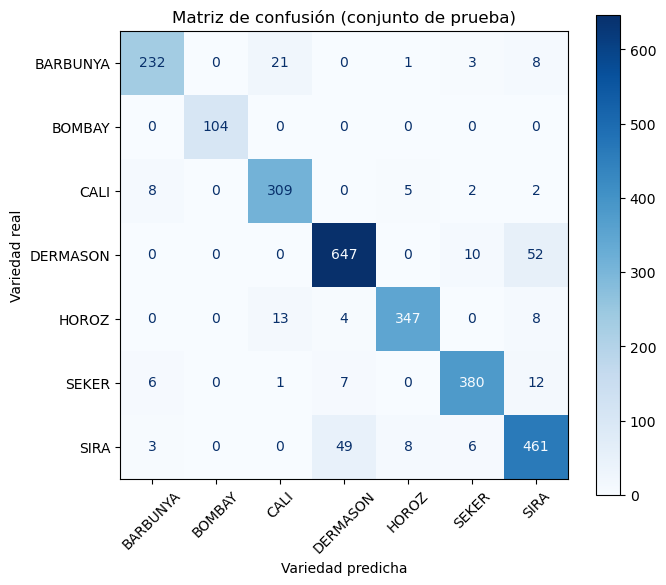

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, ax=ax, xticks_rotation=45, cmap="Blues"
)
ax.set_title("Matriz de confusión (conjunto de prueba)")
ax.set_xlabel("Variedad predicha")
ax.set_ylabel("Variedad real")
plt.tight_layout()
plt.savefig("matriz_confusion.png", dpi=150)
plt.show()

In [12]:
errores = (resultados[resultados["acierto"] == 0]
           .groupby(["clase_real", "clase_predicha"]).size()
           .sort_values(ascending=False)
           .head(5))
print("Confusiones más frecuentes (real -> predicha):")
print(errores)

Confusiones más frecuentes (real -> predicha):
clase_real  clase_predicha
DERMASON    SIRA              52
SIRA        DERMASON          49
BARBUNYA    CALI              21
HOROZ       CALI              13
SEKER       SIRA              12
dtype: int64


In [13]:
resultados.to_csv("resultados_prueba.csv", index=False)

verificacion = pd.read_csv("resultados_prueba.csv")
print("Filas guardadas:", len(verificacion))
print("Columnas:", list(verificacion.columns))
print("Exactitud desde el CSV:", verificacion["acierto"].mean().round(4))

Filas guardadas: 2709
Columnas: ['clase_real', 'clase_predicha', 'acierto']
Exactitud desde el CSV: 0.9155


**Resultados**
- Casos probados: 2,709. Aciertos: 2,480. Errores: 229.
- **Exactitud: 91.55 %.** **F1 macro: 0.927.**
- **BOMBAY** se clasifica de forma perfecta (precisión y recall de 1.00). **HOROZ** (F1 0.947) y **SEKER** (F1 0.942) también se clasifican muy bien. **SIRA** (F1 0.862) y **BARBUNYA** (F1 0.903) son las de peor resultado.

**Errores más frecuentes (real → predicha)**
- DERMASON → SIRA: 52 casos. SIRA → DERMASON: 49 casos.
- BARBUNYA → CALI: 21 casos.
- HOROZ → CALI: 13 casos.
- SEKER → SIRA: 12 casos.

**Interpretación:** DERMASON y SIRA tienen tamaños y formas parecidos (área promedio de unos 32,100 y 44,700 píxeles, y relaciones de aspecto de 1.49 y 1.57), por lo que sus frijoles quedan cerca unos de otros y a veces los vecinos más cercanos son de la otra variedad. BARBUNYA y CALI son ambas de tamaño grande. BOMBAY no se confunde porque sus frijoles son mucho más grandes que los demás (área promedio de unos 173,500 píxeles).

## 9. Una predicción de ejemplo
Se toma un frijol del conjunto de prueba, se muestran sus 16 medidas y se compara la predicción con su variedad real.

In [14]:
ejemplo = X_test.iloc[[0]]

print("Medidas del frijol de prueba:")
print(ejemplo.T)
print()
print("Predicción del modelo:", modelo.predict(ejemplo)[0])
print("Variedad real:        ", y_test.iloc[0])

Medidas del frijol de prueba:
                         1223
Area             40512.000000
Perimeter          737.636000
MajorAxisLength    248.202030
MinorAxisLength    208.525152
AspectRation         1.190274
Eccentricity         0.542365
ConvexArea       40973.000000
EquivDiameter      227.115566
Extent               0.744268
Solidity             0.988749
roundness            0.935641
Compactness          0.915043
ShapeFactor1         0.006127
ShapeFactor2         0.002650
ShapeFactor3         0.837304
ShapeFactor4         0.996621

Predicción del modelo: SEKER
Variedad real:         SEKER


## 10. Tablero en Power BI
`dashboard.pbix` se conecta a los resultados de prueba (`resultados_prueba.csv`) y muestra, en una sola página:
- tres tarjetas: **casos probados** (2,709), **aciertos** (2,480) y **exactitud** (91.55 %),
- una **matriz** con la variedad real en filas y la predicha en columnas,
- un **filtro** por variedad real.

Para abrirlo: abrir `dashboard.pbix` con Power BI Desktop. Sin filtros debe mostrar 2,709 casos y una exactitud de 91.55 %, igual que en este cuaderno.

## 11. Conclusión
- Se construyó un clasificador K-NN (StandardScaler + K-NN con k = 5) que identifica la variedad de un frijol seco a partir de 16 medidas, con una **exactitud de 91.55 %** y un **F1 macro de 0.927** sobre 2,709 frijoles que no se usaron para preparar el modelo.
- La limpieza eliminó 68 filas duplicadas antes de separar los datos, y el escalado y el modelo se ajustaron solo con entrenamiento, para que la prueba fuera un examen limpio.
- La comparación de k con validación cruzada mostró que k = 5 queda muy cerca del mejor valor (k = 19, diferencia de 0.39 puntos).
- **Limitaciones:** solo se probó K-NN; las variedades están desbalanceadas; DERMASON y SIRA se confunden por sus medidas parecidas; y las medidas vienen de imágenes tomadas en condiciones controladas, por lo que el modelo es un prototipo de apoyo y no sustituye una revisión de calidad real.